              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       2600   5.0      3.0  120.00  
2      NaN       1440   2.0      3.0   62.00  
3  Soiewre       1521   3.0      1.0   95.00  
4      NaN       1200   2.0      1.0   51.00  
(13320, 9)
<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   a

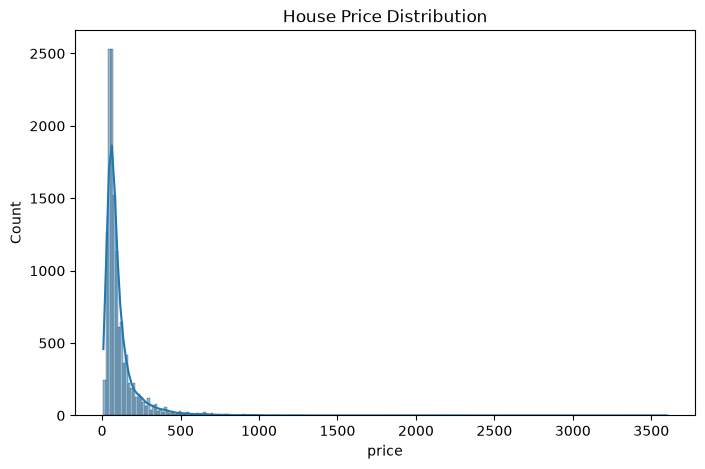

Model trained successfully

Model Evaluation
MAE: 45.299430305958744
MSE: 13665.442363863684
RMSE: 116.89928299123004
R2 Score: 0.5088340981391017
   Actual Price  Predicted Price
0          78.0        94.068666
1         125.0       109.320917
2          82.0       116.364835
3          87.0        72.043215
4         123.0       139.572231
5         110.0       194.403515
6          59.8        53.905515
7         245.0       251.495396
8          65.0        78.800934
9         160.0       187.987515


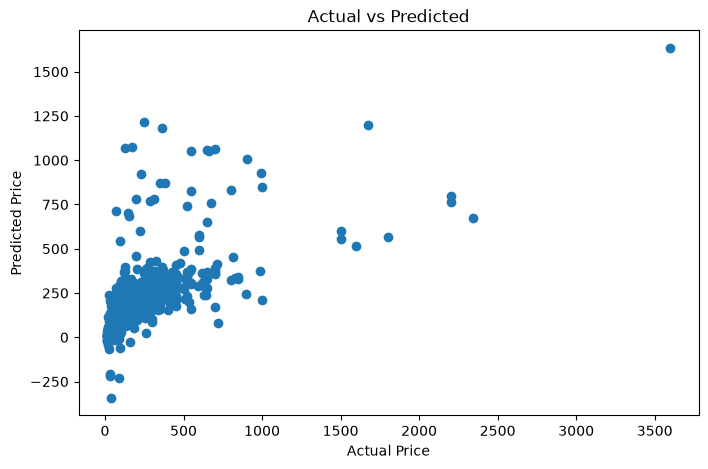

Model saved successfully

Predicted House Price:
131.0516822515412 Lakhs


In [1]:

# House Price Prediction using Linear Regression

# Import libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import joblib


# Load dataset

df = pd.read_csv("Bengaluru_House_Data.csv")

print(df.head())

print(df.shape)

print(df.info())


# EDA

print(df.isnull().sum())

print(df.duplicated().sum())

print(df.describe())


# Price distribution

plt.figure(figsize=(8,5))

sns.histplot(df["price"], kde=True)

plt.title("House Price Distribution")

plt.show()


# Data cleaning

df.drop_duplicates(inplace=True)

df.dropna(subset=["price", "location", "total_sqft"], inplace=True)

# Convert columns into numeric values

df["total_sqft"] = pd.to_numeric(df["total_sqft"], errors="coerce")

df["bath"] = pd.to_numeric(df["bath"], errors="coerce")

df["balcony"] = pd.to_numeric(df["balcony"], errors="coerce")

# Remove missing and invalid target records

df.dropna(subset=["price", "total_sqft"], inplace=True)

df = df[
    (df["total_sqft"] > 100) &
    (df["price"] > 0)
]


# Select input features

X = df[
    [
        "area_type",
        "location",
        "total_sqft",
        "bath",
        "balcony"
    ]
]

# Select target

y = df["price"]


# Train test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# Numerical columns

num_cols = ["total_sqft", "bath", "balcony"]

# Categorical columns

cat_cols = ["area_type", "location"]


# Numerical preprocessing

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Column Transformer

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])


# Create model

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])


# Train model

model.fit(X_train, y_train)

print("Model trained successfully")


# Prediction

y_pred = model.predict(X_test)


# Evaluation

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print("\nModel Evaluation")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)


# Actual vs Predicted

result = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(result.head(10))


# Graph

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")

plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted")

plt.show()


# Save model

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully")


# Predict new house price

new_house = pd.DataFrame({
    "area_type": ["Super built-up Area"],
    "location": ["Whitefield"],
    "total_sqft": [1500],
    "bath": [3],
    "balcony": [2]
})

prediction = model.predict(new_house)

print("\nPredicted House Price:")

print(prediction[0], "Lakhs")
